# Lab 3: Exploratory Data Analysis on Weather Data

## Import library

In [1948]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [1949]:
data = pd.read_csv('data/weather_feature.csv')
data.head(10)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 01:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 02:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
3,2015-01-01 03:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
4,2015-01-01 04:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
5,2015-01-01 05:00:00+01:00,Valencia,270.292,270.292,270.292,1004,71,2,321,0.0,0.0,0.0,0,800,clear,sky is clear,01n
6,2015-01-01 06:00:00+01:00,Valencia,270.292,270.292,270.292,1004,71,2,321,0.0,0.0,0.0,0,800,clear,sky is clear,01n
7,2015-01-01 07:00:00+01:00,Valencia,270.292,270.292,270.292,1004,71,2,321,0.0,0.0,0.0,0,800,clear,sky is clear,01n
8,2015-01-01 08:00:00+01:00,Valencia,274.601,274.601,274.601,1005,71,1,307,0.0,0.0,0.0,0,800,clear,sky is clear,01d
9,2015-01-01 09:00:00+01:00,Valencia,274.601,274.601,274.601,1005,71,1,307,0.0,0.0,0.0,0,800,clear,sky is clear,01d


จากการสังเกตข้อมูลพบว่า temp มีค่าอยู่หลัก 100 และค่า humidity อยู่ช่วง 70 ซึ่งมีความชื้นสูง สรุปได้ว่า temp ใช้หน่วย Kelvin

## Part 1: Data Preparation

### 1. แปลง dt_iso เป็น datetime และตั้งเป็น index

In [1950]:
print(data['dt_iso'].dtype)

object


In [1951]:
data['dt_iso'] = pd.to_datetime(data['dt_iso'], errors='coerce', utc=True)

In [1952]:
print(data['dt_iso'].dtype)

datetime64[ns, UTC]


In [1953]:
# data['dt_iso'] = data['dt_iso'].dt.date
# data

## 2. ตรวจสอบ missing values / duplicates และจัดการให้เหมาะสม

In [1954]:
data.isna().sum()

dt_iso                 0
city_name              0
temp                   0
temp_min               0
temp_max               0
pressure               0
humidity               0
wind_speed             0
wind_deg               0
rain_1h                0
rain_3h                0
snow_3h                0
clouds_all             0
weather_id             0
weather_main           0
weather_description    0
weather_icon           0
dtype: int64

In [1955]:
data.isnull().sum()

dt_iso                 0
city_name              0
temp                   0
temp_min               0
temp_max               0
pressure               0
humidity               0
wind_speed             0
wind_deg               0
rain_1h                0
rain_3h                0
snow_3h                0
clouds_all             0
weather_id             0
weather_main           0
weather_description    0
weather_icon           0
dtype: int64

## 3. สร้างฟีเจอร์ใหม่: hour, day, month, is_weekend

In [1956]:
# ----------------------------- #
# 1) รายชั่วโมง (ต้นฉบับ)
df_hour = data.copy()                     # มีอยู่แล้ว

# ----------------------------- #
# 2) รายวัน (ค่าเฉลี่ย / ผลรวม)
agg_map = {
    'temp':       'mean',
    'humidity':   'mean',
    'pressure':   'mean',
    'wind_speed': 'mean',
    'rain_1h':    'sum',
    'snow_3h':    'sum',
    'clouds_all': 'mean',
    'weather_main': lambda s: s.mode().iat[0] if not s.mode().empty else np.nan
}

df_day = (
    data
    .set_index('dt_iso')
    .groupby('city_name')  
    .resample('D')           # ‘D’ = 1 วัน
    .agg(agg_map)
    .reset_index()
)

# ----------------------------- #
# 3) รายเดือน (ค่าเฉลี่ย / ผลรวม)
df_month = (
    data
    .set_index('dt_iso')
    .resample('M')           # ‘M’ = วันสิ้นเดือน
    .agg(agg_map)
    .reset_index()
)

# ----------------------------- #
# 4) เพิ่มคอลัมน์ is_weekend ในระดับ “วัน”
df_day['is_weekend'] = df_day['dt_iso'].dt.dayofweek >= 5  # Sat(5), Sun(6)

#   • ถ้าต้องการ DataFrame เฉพาะเสาร์‑อาทิตย์
df_weekend = df_day[df_day['is_weekend']].reset_index(drop=True)

# ----------------------------- #


C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\1382469739.py:32: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M')           # ‘M’ = วันสิ้นเดือน


In [1957]:
df_hour.head(10)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2014-12-31 23:00:00+00:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 00:00:00+00:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 01:00:00+00:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
3,2015-01-01 02:00:00+00:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
4,2015-01-01 03:00:00+00:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
5,2015-01-01 04:00:00+00:00,Valencia,270.292,270.292,270.292,1004,71,2,321,0.0,0.0,0.0,0,800,clear,sky is clear,01n
6,2015-01-01 05:00:00+00:00,Valencia,270.292,270.292,270.292,1004,71,2,321,0.0,0.0,0.0,0,800,clear,sky is clear,01n
7,2015-01-01 06:00:00+00:00,Valencia,270.292,270.292,270.292,1004,71,2,321,0.0,0.0,0.0,0,800,clear,sky is clear,01n
8,2015-01-01 07:00:00+00:00,Valencia,274.601,274.601,274.601,1005,71,1,307,0.0,0.0,0.0,0,800,clear,sky is clear,01d
9,2015-01-01 08:00:00+00:00,Valencia,274.601,274.601,274.601,1005,71,1,307,0.0,0.0,0.0,0,800,clear,sky is clear,01d


In [1958]:
df_day.head(10)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
0,Barcelona,2014-12-31 00:00:00+00:00,281.625000,100.000000,1035.000000,7.000000,0.0,0.0,0.000000,clear,False
1,Barcelona,2015-01-01 00:00:00+00:00,282.536029,90.458333,1036.708333,4.041667,0.0,0.0,0.000000,clear,False
2,Barcelona,2015-01-02 00:00:00+00:00,283.804125,91.125000,1037.458333,1.750000,0.0,0.0,12.666667,clear,False
3,Barcelona,2015-01-03 00:00:00+00:00,284.570939,85.958333,1034.041667,2.250000,0.0,0.0,3.000000,clear,True
4,Barcelona,2015-01-04 00:00:00+00:00,286.616438,68.625000,1027.458333,1.208333,0.0,0.0,2.500000,clear,True
5,Barcelona,2015-01-05 00:00:00+00:00,285.101936,72.708333,1025.791667,2.208333,0.0,0.0,5.625000,clear,False
6,Barcelona,2015-01-06 00:00:00+00:00,284.828333,72.625000,1021.833333,1.041667,0.0,0.0,38.750000,clouds,False
7,Barcelona,2015-01-07 00:00:00+00:00,284.286104,77.000000,1027.458333,1.166667,2.7,0.0,41.000000,clouds,False
8,Barcelona,2015-01-08 00:00:00+00:00,284.851947,70.750000,1032.541667,1.416667,0.0,0.0,0.000000,clear,False
9,Barcelona,2015-01-09 00:00:00+00:00,284.303660,58.625000,1036.375000,1.541667,0.0,0.0,0.458333,clear,False


In [1959]:
df_month.head(10)

,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main
0,2014-12-31 00:00:00+00:00,272.491463,82.400000,1016.400000,2.000000,0.0,0.000,0.000000,clear
1,2015-01-31 00:00:00+00:00,280.160484,74.272239,1011.518409,2.773179,523.5,72.375,26.794410,clear
2,2015-02-28 00:00:00+00:00,281.200904,71.226786,3822.709524,3.528274,785.1,725.700,38.500000,clear
3,2015-03-31 00:00:00+00:00,284.409967,72.949490,1017.930414,2.520150,1306.2,47.301,33.537077,clear
4,2015-04-30 00:00:00+00:00,287.221759,69.419167,1014.331111,2.287778,429.9,0.000,33.368056,clouds
5,2015-05-31 00:00:00+00:00,291.916534,62.032796,1003.094892,2.474462,441.0,0.000,23.930108,clear
6,2015-06-30 00:00:00+00:00,295.696363,61.351381,1008.583702,2.193370,460.5,0.000,18.352762,clear
7,2015-07-31 00:00:00+00:00,300.364389,56.884892,1015.842526,2.564082,141.0,0.000,18.853184,clear
8,2015-08-31 00:00:00+00:00,298.494090,59.669061,1015.291035,2.648045,255.0,0.000,20.471136,clouds
9,2015-09-30 00:00:00+00:00,293.360495,64.388158,1015.927906,2.525219,308.7,0.000,24.402961,clouds


In [1960]:
df_weekend.head(10)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
0,Barcelona,2015-01-03 00:00:00+00:00,284.570939,85.958333,1034.041667,2.250000,0.0,0.0,3.000000,clear,True
1,Barcelona,2015-01-04 00:00:00+00:00,286.616438,68.625000,1027.458333,1.208333,0.0,0.0,2.500000,clear,True
2,Barcelona,2015-01-10 00:00:00+00:00,285.353208,65.291667,1028.041667,2.000000,0.0,0.0,0.000000,clear,True
3,Barcelona,2015-01-11 00:00:00+00:00,287.300973,72.041667,1025.000000,1.458333,0.3,0.0,10.583333,clear,True
4,Barcelona,2015-01-17 00:00:00+00:00,283.065833,57.708333,1015.333333,1.833333,1.2,0.0,10.666667,clear,True
5,Barcelona,2015-01-18 00:00:00+00:00,282.778750,52.333333,1011.333333,2.666667,2.1,0.0,43.000000,clouds,True
6,Barcelona,2015-01-24 00:00:00+00:00,283.167625,46.708333,1014.833333,1.958333,0.0,0.0,1.000000,clear,True
7,Barcelona,2015-01-25 00:00:00+00:00,284.605083,19.375000,1016.208333,4.083333,0.0,0.0,0.000000,clear,True
8,Barcelona,2015-01-31 00:00:00+00:00,283.279978,57.250000,986.708333,2.208333,2.1,0.0,13.333333,clear,True
9,Barcelona,2015-02-01 00:00:00+00:00,281.500542,36.458333,999.166667,2.750000,0.0,0.0,11.416667,clear,True


## 4. แสดง Descriptive Statistics และจำนวน Missing Value ก่อนและหลัง 

In [1961]:
df_hour.describe()

,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id
count,178396.000000,178396.000000,178396.000000,1.783960e+05,178396.000000,178396.00000,178396.000000,178396.000000,178396.000000,178396.000000,178396.000000,178396.000000
mean,289.618605,288.330442,291.091267,1.069261e+03,68.423457,2.47056,166.591190,0.075492,0.000380,0.004763,25.073292,759.831902
std,8.026199,7.955491,8.612454,5.969632e+03,21.902888,2.09591,116.611927,0.398847,0.007288,0.222604,30.774129,108.733223
min,262.240000,262.240000,262.240000,0.000000e+00,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,200.000000
25%,283.670000,282.483602,284.650000,1.013000e+03,53.000000,1.00000,55.000000,0.000000,0.000000,0.000000,0.000000,800.000000
50%,289.150000,288.150000,290.150000,1.018000e+03,72.000000,2.00000,177.000000,0.000000,0.000000,0.000000,20.000000,800.000000
75%,295.150000,293.730125,297.150000,1.022000e+03,87.000000,4.00000,270.000000,0.000000,0.000000,0.000000,40.000000,801.000000
max,315.600000,315.150000,321.150000,1.008371e+06,100.000000,133.00000,360.000000,12.000000,2.315000,21.500000,100.000000,804.000000


In [1962]:
def summary_stats(df):
    out = df.describe().T          # descriptive
    out['missing_before'] = df.isna().sum()
    out['missing_after']  = df.dropna().isna().sum()   # 0 หลัง drop
    return out

summ_hour     = summary_stats(df_hour)
summ_day      = summary_stats(df_day)
summ_month    = summary_stats(df_month)
summ_weekend  = summary_stats(df_weekend)

In [1963]:
summ_hour

,count,mean,std,min,25%,50%,75%,max,missing_before,missing_after
temp,178396.0,289.618605,8.026199,262.24,283.670000,289.15,295.150000,315.600,0,0
temp_min,178396.0,288.330442,7.955491,262.24,282.483602,288.15,293.730125,315.150,0,0
temp_max,178396.0,291.091267,8.612454,262.24,284.650000,290.15,297.150000,321.150,0,0
pressure,178396.0,1069.260740,5969.631893,0.00,1013.000000,1018.00,1022.000000,1008371.000,0,0
humidity,178396.0,68.423457,21.902888,0.00,53.000000,72.00,87.000000,100.000,0,0
wind_speed,178396.0,2.470560,2.095910,0.00,1.000000,2.00,4.000000,133.000,0,0
wind_deg,178396.0,166.591190,116.611927,0.00,55.000000,177.00,270.000000,360.000,0,0
rain_1h,178396.0,0.075492,0.398847,0.00,0.000000,0.00,0.000000,12.000,0,0
rain_3h,178396.0,0.000380,0.007288,0.00,0.000000,0.00,0.000000,2.315,0,0
snow_3h,178396.0,0.004763,0.222604,0.00,0.000000,0.00,0.000000,21.500,0,0


In [1964]:
summ_day

,count,mean,std,min,25%,50%,75%,max,missing_before,missing_after
temp,7310.0,289.684443,7.131855,267.325,284.174380,289.181240,295.272625,308.306250,0,0
humidity,7310.0,68.131316,16.541079,8.125,57.875000,70.724537,80.708333,100.000000,0,0
pressure,7310.0,1070.161293,3042.922331,928.875,1013.333333,1017.416667,1021.875000,227928.541667,0,0
wind_speed,7310.0,2.470803,1.376032,0.000,1.541667,2.166667,3.041667,24.875000,0,0
rain_1h,7310.0,1.842331,6.093341,0.000,0.000000,0.000000,0.900000,82.500000,0,0
snow_3h,7310.0,0.116236,4.613290,0.000,0.000000,0.000000,0.000000,316.500000,0,0
clouds_all,7310.0,24.518779,24.138543,0.000,3.333333,16.666667,40.000000,93.333333,0,0


In [1965]:
summ_month

,count,mean,std,min,25%,50%,75%,max,missing_before,missing_after
temp,49.0,289.274921,6.590362,272.491463,284.176995,288.668005,295.696363,300.364389,0,0
humidity,49.0,68.670043,7.350953,55.884426,62.032796,69.020987,74.272239,82.745403,0,0
pressure,49.0,1073.645829,400.939816,998.742742,1014.168643,1015.881915,1019.214874,3822.709524,0,0
wind_speed,49.0,2.463317,0.493684,1.623118,2.203010,2.370351,2.624573,4.134843,0,0
rain_1h,49.0,274.845714,243.720019,0.000000,115.500000,230.700000,327.000000,1306.200000,0,0
snow_3h,49.0,17.340510,104.022428,0.000000,0.000000,0.000000,0.000000,725.700000,0,0
clouds_all,49.0,24.582970,7.287497,0.000000,19.562569,23.835233,29.887276,38.500000,0,0


In [1966]:
summ_weekend

,count,mean,std,min,25%,50%,75%,max,missing_before,missing_after
temp,2090.0,289.700602,7.101716,272.067771,284.282453,289.198833,295.104300,307.887500,0,0
humidity,2090.0,68.166765,16.638743,8.125000,58.062500,70.729167,80.739583,100.000000,0,0
pressure,2090.0,1180.442940,5581.406623,928.875000,1013.083333,1017.375000,1021.838333,227928.541667,0,0
wind_speed,2090.0,2.504894,1.408106,0.291667,1.583333,2.166667,3.083333,11.333333,0,0
rain_1h,2090.0,2.045091,6.652456,0.000000,0.000000,0.000000,1.200000,79.800000,0,0
snow_3h,2090.0,0.023186,0.730739,0.000000,0.000000,0.000000,0.000000,30.375000,0,0
clouds_all,2090.0,25.015749,24.232449,0.000000,3.708333,17.937500,40.704327,93.333333,0,0


## Part 2: EDA & Visualization อย่างน้อย 5 ชนิด (เลือกได้ตามอิสระ)

## 1. Line plot Temperature ในแต่ละเมือง

### ใน city_name มีเมืองอยู่ทั้งหมด 5 เมือง ซึ่งทั้งหมดนี้อยู่ในประเทศสเปน

In [1967]:
data['city_name'].unique()

array(['Valencia', 'Madrid', 'Bilbao', ' Barcelona', 'Seville'],
      dtype=object)

In [1968]:
df_day['city_name'] = df_day['city_name'].str.strip()

In [1969]:
valencia_data = df_day[df_day['city_name'] == 'Valencia']
madrid_data   = df_day[df_day['city_name'] == 'Madrid']
bilbao_data   = df_day[df_day['city_name'] == 'Bilbao']
barcelona_data = df_day[df_day['city_name'] == 'Barcelona']
seville_data  = df_day[df_day['city_name'] == 'Seville']

In [1970]:
valencia_data.head(5)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
5848,Valencia,2014-12-31 00:00:00+00:00,270.475000,77.000000,1001.000000,1.000000,0.0,0.0,0.0,clear,False
5849,Valencia,2015-01-01 00:00:00+00:00,275.986987,69.958333,1010.208333,1.000000,0.0,0.0,0.0,clear,False
5850,Valencia,2015-01-02 00:00:00+00:00,276.784833,67.708333,1013.875000,1.125000,0.0,0.0,0.0,clear,False
5851,Valencia,2015-01-03 00:00:00+00:00,279.203802,70.000000,1007.208333,1.833333,0.0,0.0,2.5,clear,True
5852,Valencia,2015-01-04 00:00:00+00:00,279.260000,75.250000,1003.541667,1.333333,0.0,0.0,0.0,clear,True


In [1971]:
madrid_data.head(5)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
2924,Madrid,2014-12-31 00:00:00+00:00,267.325000,63.000000,971.000000,1.000000,0.0,0.0,0.000000,clear,False
2925,Madrid,2015-01-01 00:00:00+00:00,272.176652,62.583333,988.500000,0.875000,0.0,0.0,0.000000,clear,False
2926,Madrid,2015-01-02 00:00:00+00:00,272.546417,64.583333,992.250000,1.000000,0.0,0.0,5.291667,clear,False
2927,Madrid,2015-01-03 00:00:00+00:00,273.754031,66.250000,981.125000,0.958333,0.0,0.0,0.000000,clear,True
2928,Madrid,2015-01-04 00:00:00+00:00,274.543271,67.416667,974.208333,0.958333,0.0,0.0,0.000000,clear,True


In [1972]:
bilbao_data.head(5)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
1462,Bilbao,2014-12-31 00:00:00+00:00,269.657312,97.000000,1036.000000,0.000000,0.0,0.0,0.000000,clear,False
1463,Bilbao,2015-01-01 00:00:00+00:00,275.146669,82.083333,1035.666667,0.875000,0.0,0.0,4.250000,clear,False
1464,Bilbao,2015-01-02 00:00:00+00:00,276.177753,83.125000,1037.458333,0.958333,0.0,0.0,13.500000,clouds,False
1465,Bilbao,2015-01-03 00:00:00+00:00,276.498622,83.750000,1036.166667,0.791667,0.0,0.0,3.916667,clear,True
1466,Bilbao,2015-01-04 00:00:00+00:00,277.213458,94.666667,1035.125000,0.708333,5.4,0.0,55.541667,rain,True


In [1973]:
barcelona_data.head(5)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
0,Barcelona,2014-12-31 00:00:00+00:00,281.625000,100.000000,1035.000000,7.000000,0.0,0.0,0.000000,clear,False
1,Barcelona,2015-01-01 00:00:00+00:00,282.536029,90.458333,1036.708333,4.041667,0.0,0.0,0.000000,clear,False
2,Barcelona,2015-01-02 00:00:00+00:00,283.804125,91.125000,1037.458333,1.750000,0.0,0.0,12.666667,clear,False
3,Barcelona,2015-01-03 00:00:00+00:00,284.570939,85.958333,1034.041667,2.250000,0.0,0.0,3.000000,clear,True
4,Barcelona,2015-01-04 00:00:00+00:00,286.616438,68.625000,1027.458333,1.208333,0.0,0.0,2.500000,clear,True


In [1974]:
seville_data.head(5)

,city_name,dt_iso,temp,humidity,pressure,wind_speed,rain_1h,snow_3h,clouds_all,weather_main,is_weekend
4386,Seville,2014-12-31 00:00:00+00:00,273.375000,75.000000,1039.000000,1.000000,0.0,0.0,0.0,clear,False
4387,Seville,2015-01-01 00:00:00+00:00,279.159695,72.250000,1039.541667,2.875000,0.0,0.0,0.0,clear,False
4388,Seville,2015-01-02 00:00:00+00:00,280.442958,82.916667,1042.416667,3.041667,0.0,0.0,0.0,clear,False
4389,Seville,2015-01-03 00:00:00+00:00,280.121238,84.125000,1043.333333,1.958333,0.0,0.0,0.0,clear,True
4390,Seville,2015-01-04 00:00:00+00:00,280.583604,80.833333,1039.708333,2.041667,0.0,0.0,0.0,clear,True


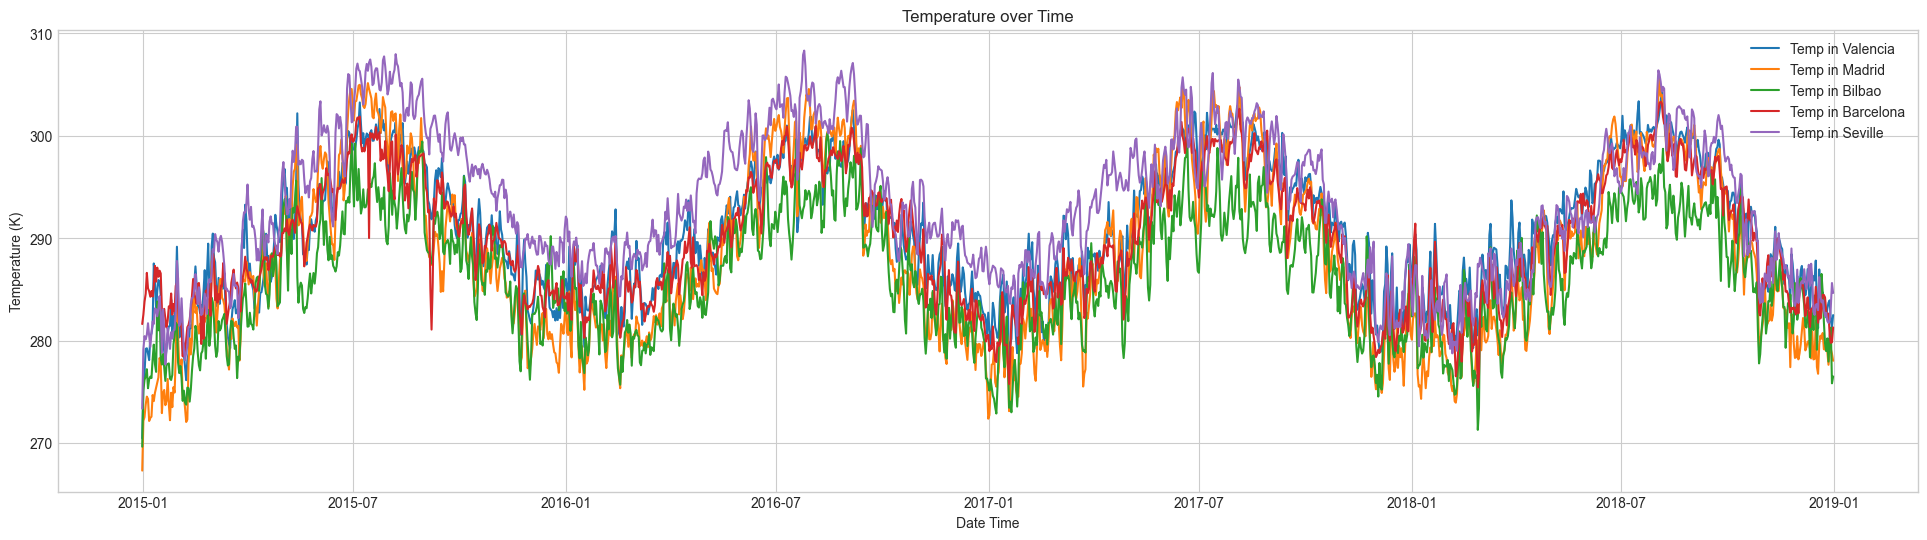

In [1975]:
plt.figure(figsize=(24, 6))
plt.plot(valencia_data['dt_iso'], valencia_data['temp'], label='Temp in Valencia')
plt.plot(madrid_data['dt_iso'], madrid_data['temp'], label='Temp in Madrid')
plt.plot(bilbao_data['dt_iso'], bilbao_data['temp'], label='Temp in Bilbao')
plt.plot(barcelona_data['dt_iso'], barcelona_data['temp'], label='Temp in Barcelona')
plt.plot(seville_data['dt_iso'], seville_data['temp'], label='Temp in Seville')

plt.xlabel('Date Time')
plt.ylabel('Temperature (K)')
plt.title('Temperature over Time')
plt.legend()
plt.grid(True)
plt.show()

### เทียบค่า temp เมือง valencia กับเมืองต่างๆ

#### Valencia and Madrid

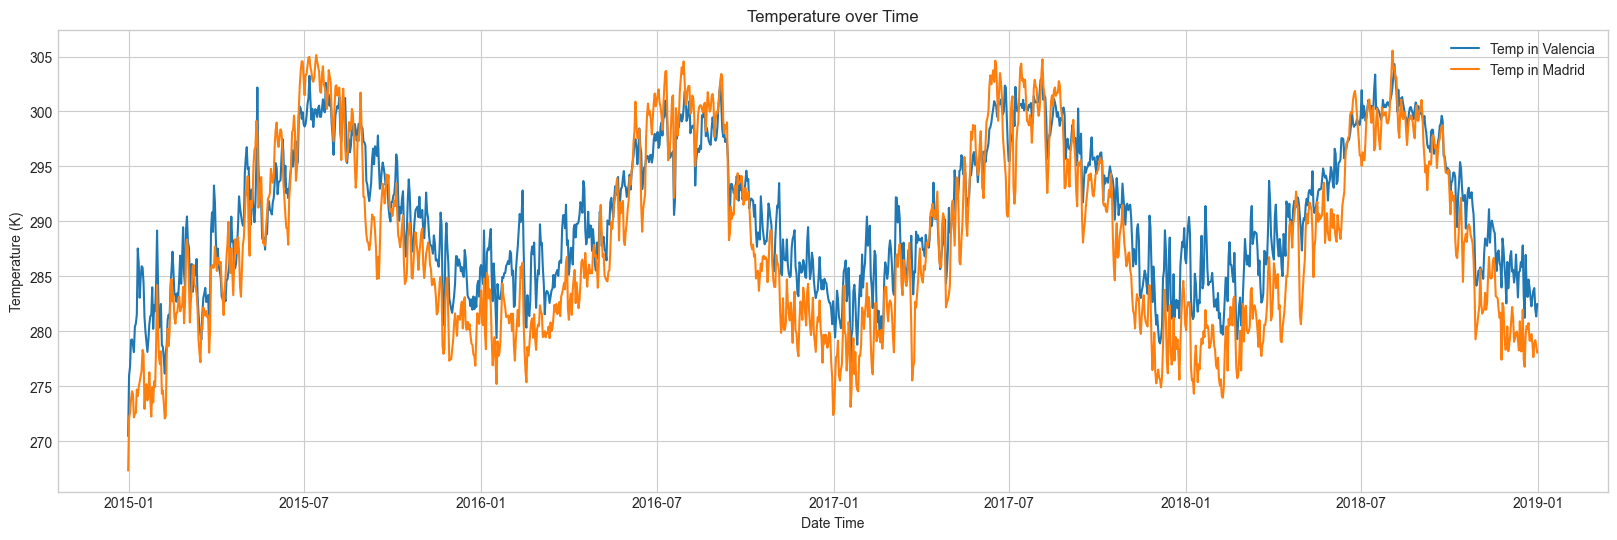

In [1976]:
plt.figure(figsize=(20, 6))
plt.plot(valencia_data['dt_iso'], valencia_data['temp'], label='Temp in Valencia')
plt.plot(madrid_data['dt_iso'], madrid_data['temp'], label='Temp in Madrid')

plt.xlabel('Date Time')
plt.ylabel('Temperature (K)')
plt.title('Temperature over Time')
plt.legend()
plt.grid(True)
plt.show()

#### Valencia and Bilbao

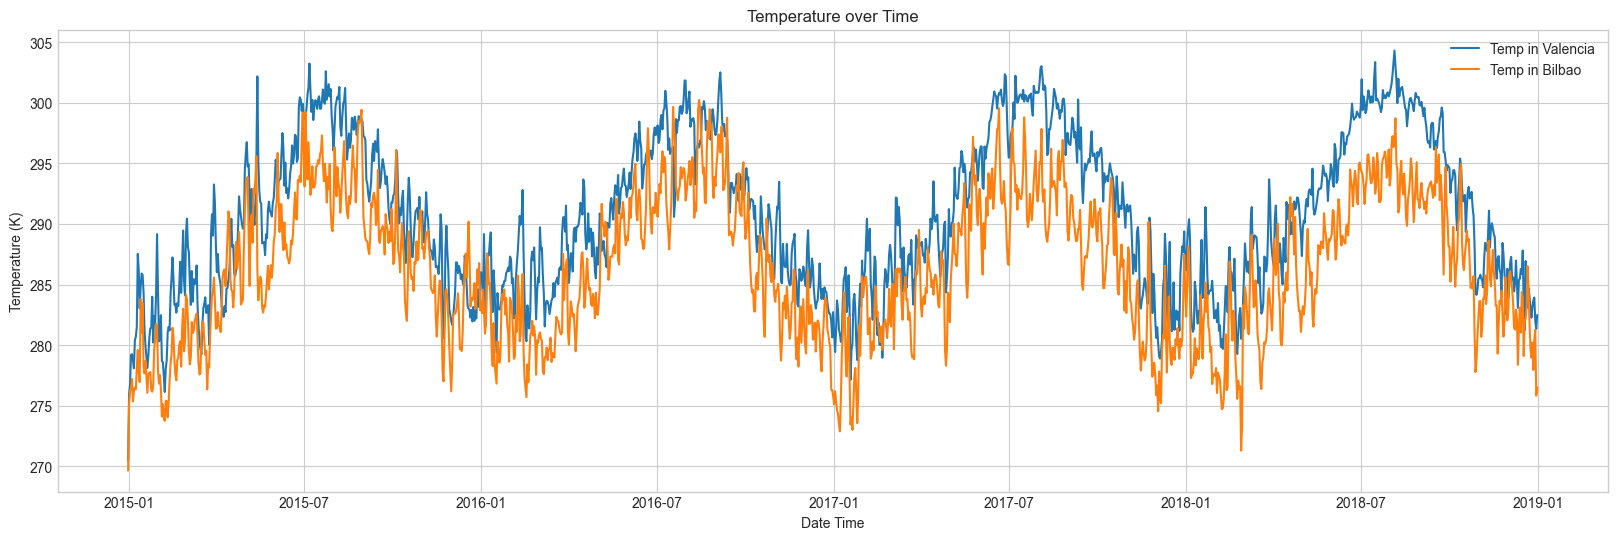

In [1977]:
plt.figure(figsize=(20, 6))
plt.plot(valencia_data['dt_iso'], valencia_data['temp'], label='Temp in Valencia')
plt.plot(bilbao_data['dt_iso'], bilbao_data['temp'], label='Temp in Bilbao')

plt.xlabel('Date Time')
plt.ylabel('Temperature (K)')
plt.title('Temperature over Time')
plt.legend()
plt.grid(True)
plt.show()

#### Valencia and Barcelona

ค่า temp ของทั้ง 2 เมืองมีความใกล้เคียงกันมาก

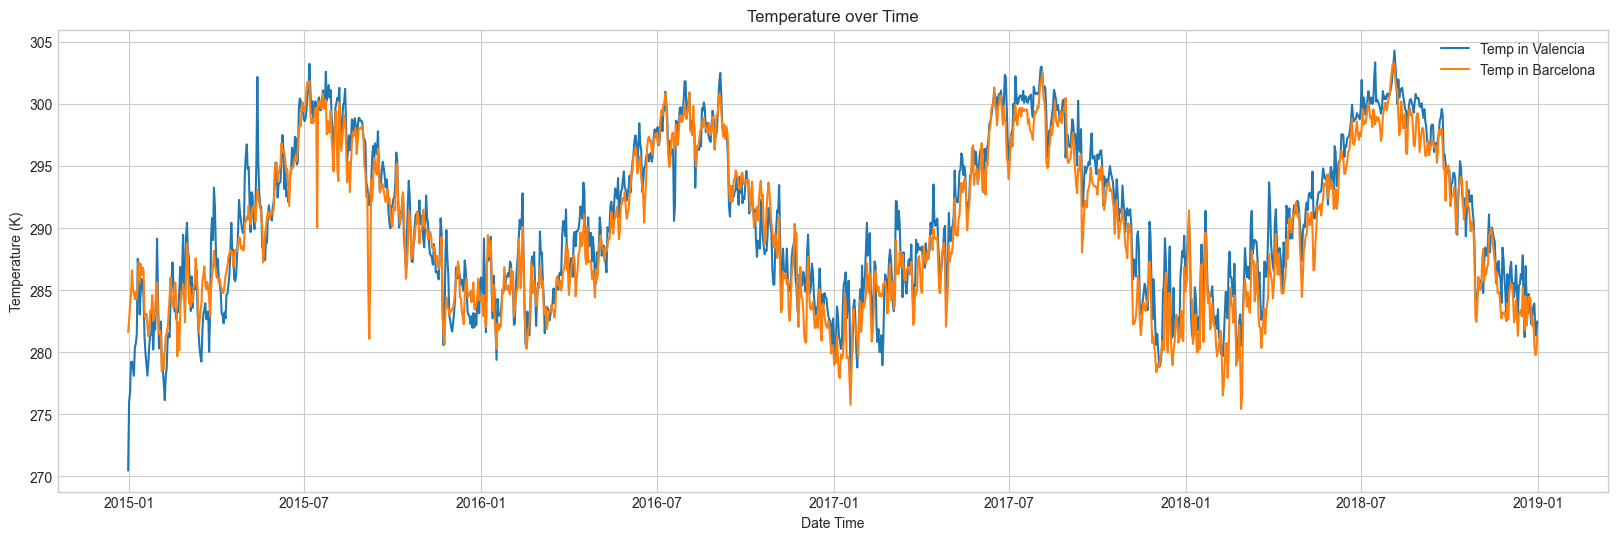

In [1978]:
plt.figure(figsize=(20, 6))
plt.plot(valencia_data['dt_iso'], valencia_data['temp'], label='Temp in Valencia')
plt.plot(barcelona_data['dt_iso'], barcelona_data['temp'], label='Temp in Barcelona')

plt.xlabel('Date Time')
plt.ylabel('Temperature (K)')
plt.title('Temperature over Time')
plt.legend()
plt.grid(True)
plt.show()

#### Valencia and Seville

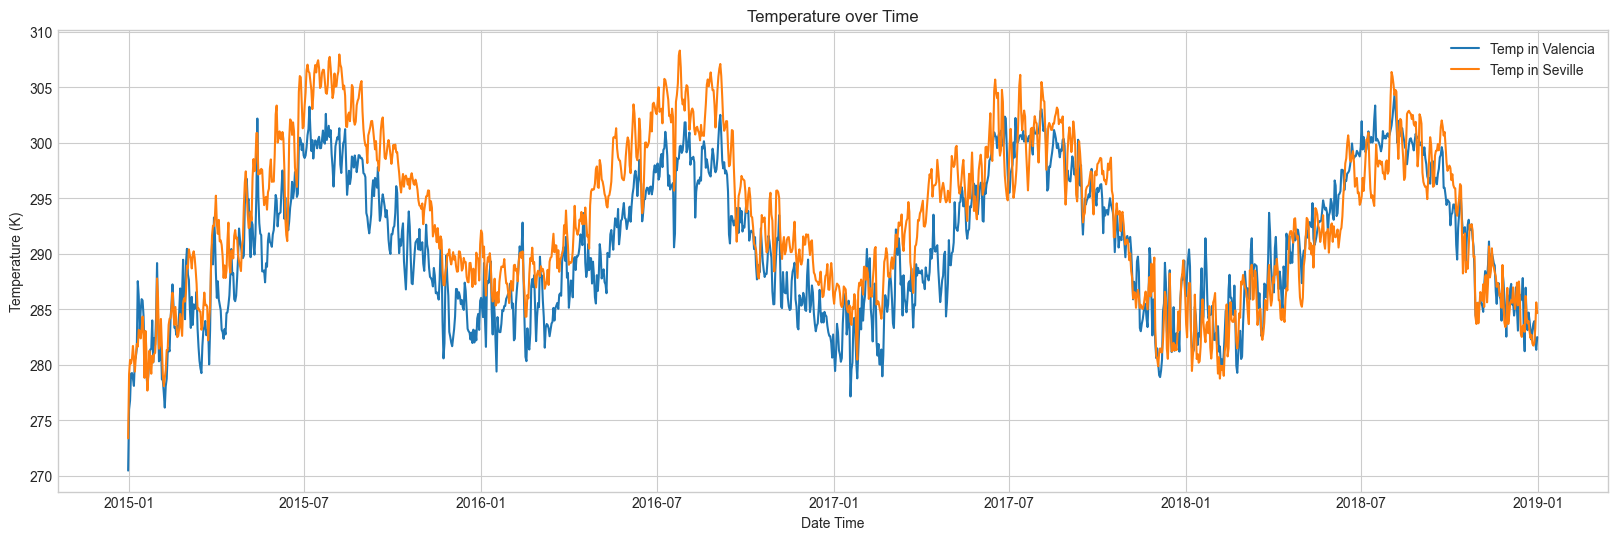

In [1979]:
plt.figure(figsize=(20, 6))
plt.plot(valencia_data['dt_iso'], valencia_data['temp'], label='Temp in Valencia')
plt.plot(seville_data['dt_iso'], seville_data['temp'], label='Temp in Seville')

plt.xlabel('Date Time')
plt.ylabel('Temperature (K)')
plt.title('Temperature over Time')
plt.legend()
plt.grid(True)
plt.show()

### จากกราฟเปรียบเทียบอุณหภูมิของเมือง Valencia กับเมืองอื่น ๆ ทั้ง 5 เมือง ได้แก่ Madrid, Bilbao, Barcelona และ Seville พบว่า ค่าอุณหภูมิโดยรวมมีแนวโน้มใกล้เคียงกัน โดยเฉพาะ เมือง Barcelona มีรูปแบบอุณหภูมิที่ใกล้เคียงกับ Valencia มากที่สุด ซึ่งอาจเนื่องมาจากลักษณะทางภูมิศาสตร์ที่คล้ายคลึงกัน เช่น เป็นเมืองชายฝั่งทะเลเมดิเตอร์เรเนียน ทำให้ได้รับอิทธิพลจากทะเลในลักษณะคล้ายกัน

## 2. Pie plot weather main ต่างๆของทุกเมือง

In [1980]:
data['weather_main'].unique()

array(['clear', 'clouds', 'rain', 'mist', 'thunderstorm', 'drizzle',
       'fog', 'smoke', 'haze', 'snow', 'dust', 'squall'], dtype=object)

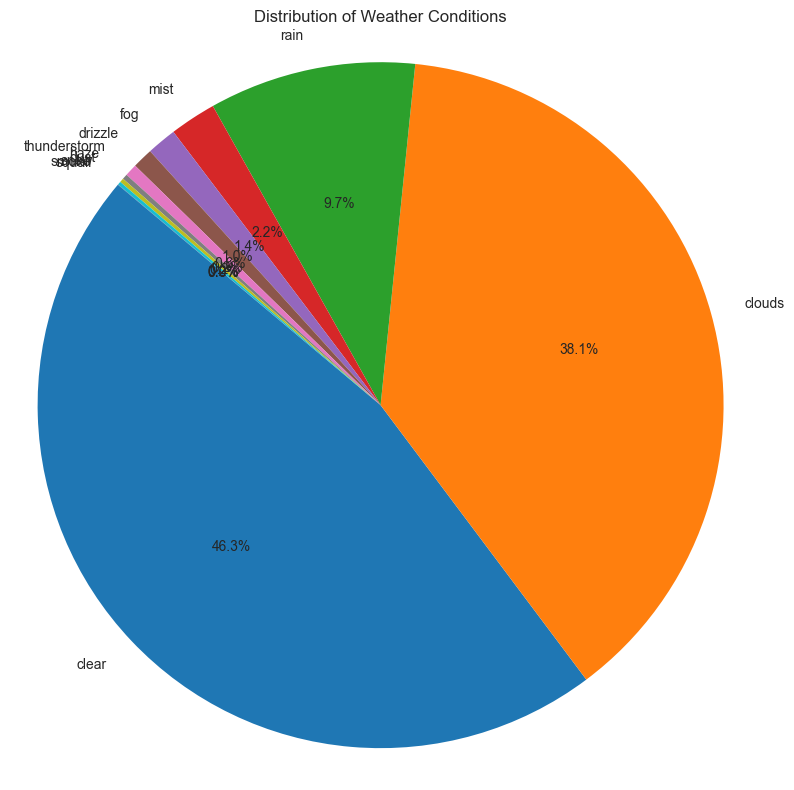

In [1981]:
weather_counts = data['weather_main'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    weather_counts,
    labels=weather_counts.index,
    autopct='%1.1f%%',
    startangle=140
)
plt.title('Distribution of Weather Conditions')
plt.axis('equal')
plt.tight_layout()
plt.show()


อันบนอ่านยากใช่ไหม? ลองดูอันล่าง 

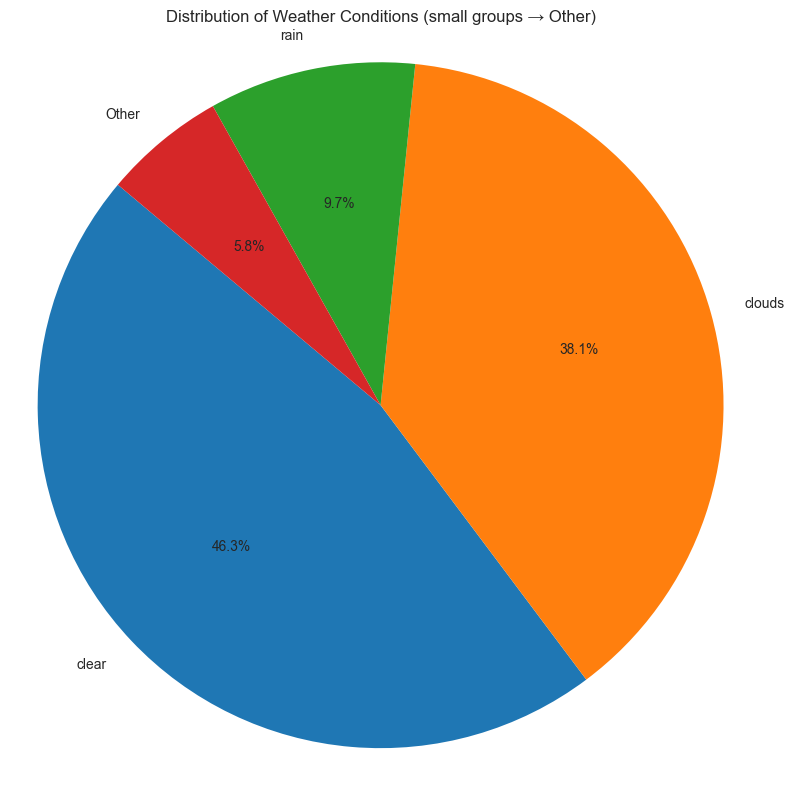

In [1982]:
# ---------- 1) เลือกเกณฑ์ ----------
total   = len(data)          # ข้อมูลทั้งหมด
pct_cut = 0.05               # < 5 % ของทั้งชุดจะถูกจับรวม

# ---------- 2) หา label ที่ควรถูกรวม ----------
vc = data['weather_main'].value_counts()
small_labels = vc[vc < pct_cut * total].index     

# ---------- 3) สร้างคอลัมน์ใหม่ที่รวมหมวดเล็ก ----------
data['weather_grp'] = np.where(
    data['weather_main'].isin(small_labels),
    'Other',
    data['weather_main']
)

# ---------- 4) นับอีกครั้งหลังรวม ----------
pie_counts = data['weather_grp'].value_counts().sort_values(ascending=False)

# ---------- 5) วาดกราฟ ----------
plt.figure(figsize=(8, 8))
plt.pie(
    pie_counts,
    labels=pie_counts.index,
    autopct='%1.1f%%',
    startangle=140
)
plt.title('Distribution of Weather Conditions (small groups → Other)')
plt.axis('equal')
plt.tight_layout()
plt.show()


###  กราฟวงกลมแสดงสัดส่วนของข้อมูลสภาพอากาศ (weather main) โดยประเภท 'clear' พบมากที่สุดคิดเป็น 46.3% รองลงมาคือ 'clouds' 38.1% และ 'rain' 9.7% ส่วนประเภทอื่นๆ เช่น mist, thunderstorm, drizzle, fog, smoke, haze, snow, dust และ squall รวมกันคิดเป็น 5.8%

## 3. Box plot

In [1983]:
mask_valencia = data['city_name'].str.lower() == 'valencia'

weather_types = data.loc[mask_valencia, 'weather_main'].unique()
print("Weather types in Valencia:", weather_types)

Weather types in Valencia: ['clear' 'clouds' 'rain' 'mist' 'thunderstorm' 'drizzle' 'fog' 'smoke'
 'haze']


In [1984]:
data['city_name'] = data['city_name'].str.strip()

In [1985]:
valencia_weather_main = data[data['city_name'] == 'Valencia']
madrid_weather_main = data[data['city_name'] == 'Madrid']
bilbao_weather_main = data[data['city_name'] == 'Bilbao']
barcelona_weather_main = data[data['city_name'] == 'Barcelona']
seville_weather_main = data[data['city_name'] == 'Seville']


In [1986]:
valencia_weather_main.head(5)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon,weather_grp
0,2014-12-31 23:00:00+00:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n,clear
1,2015-01-01 00:00:00+00:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n,clear
2,2015-01-01 01:00:00+00:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n,clear
3,2015-01-01 02:00:00+00:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n,clear
4,2015-01-01 03:00:00+00:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n,clear


C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\1571419688.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valencia_weather_main, x='weather_main', y='dt_iso', palette='pastel')


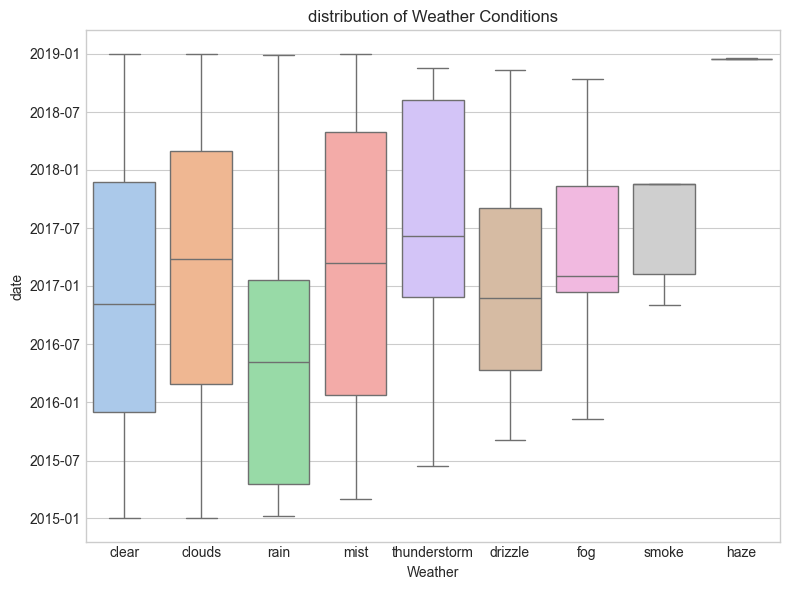

In [1987]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=valencia_weather_main, x='weather_main', y='dt_iso', palette='pastel')
plt.title('distribution of Weather Conditions')
plt.xlabel('Weather')
plt.ylabel('date')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\2346740699.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\2346740699.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\2346740699.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\2346740699.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `h

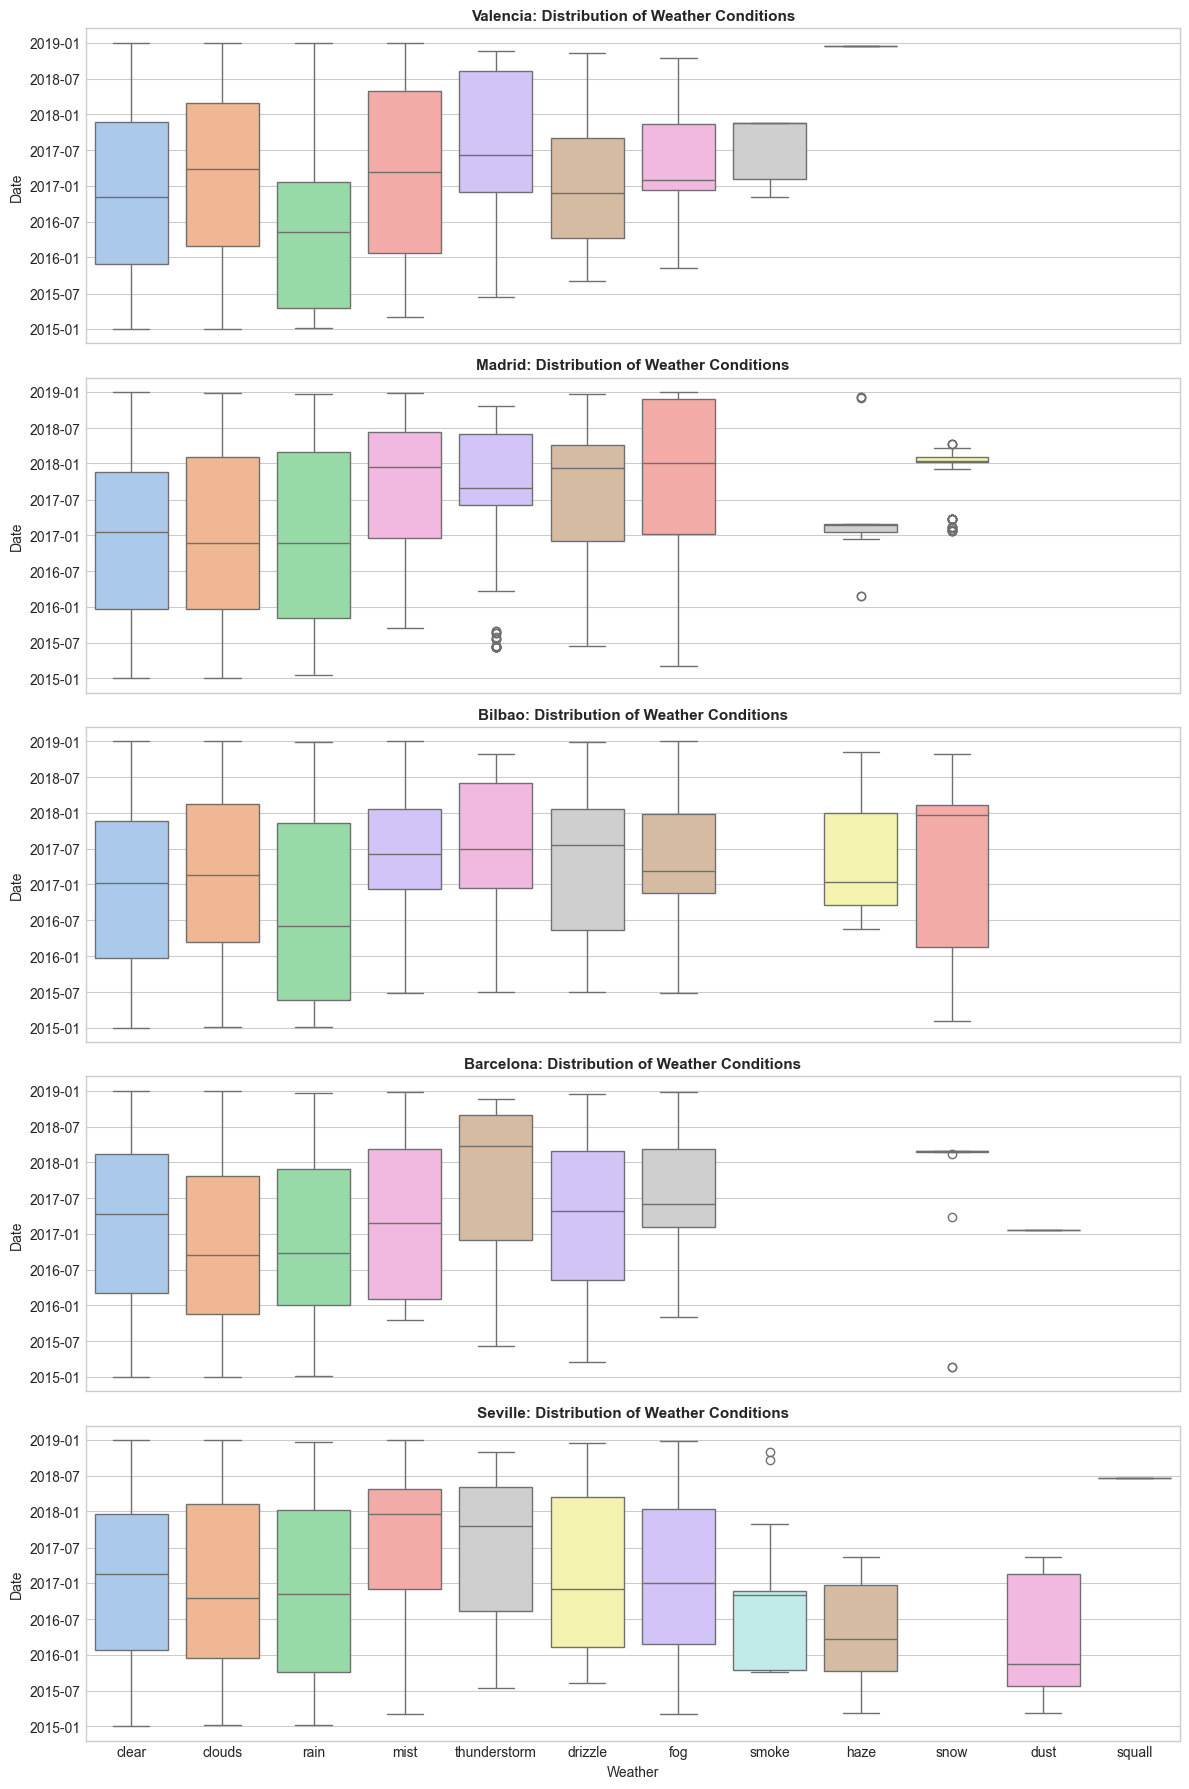

In [1988]:
# --- เตรียมรายชื่อเมืองที่ต้องการ ---
cities = ['Valencia', 'Madrid', 'Bilbao', 'Barcelona', 'Seville']

# --- สร้างกริด subplot (5 แถว 1 คอลัมน์) ---
fig, axes = plt.subplots(
    nrows=len(cities), ncols=1,
    figsize=(12, 18),        # ปรับสูงพอให้แต่ละกราฟไม่เบียดกัน
    sharex=True             # แชร์แกน X (weather_main) ร่วมกัน
)

# --- วาด boxplot ทีละเมือง ---
for ax, city in zip(axes, cities):
    subset = data[data['city_name'] == city]
    sns.boxplot(
        data=subset,
        x='weather_main',
        y='dt_iso',
        palette='pastel',
        ax=ax
    )
    ax.set_title(f'{city}: Distribution of Weather Conditions', fontsize=11, weight='bold')
    ax.set_xlabel('')      # ซ่อน label X ด้านใน (แสดงเฉพาะแถวล่าง)
    ax.set_ylabel('Date')

# label X ใต้กราฟล่างสุด
axes[-1].set_xlabel('Weather')

plt.tight_layout()
plt.show()

### จากกราฟ Box Plot ซึ่งแสดงการกระจายของสภาพอากาศหลัก (weather main) ในแต่ละช่วงเวลา พบว่าใน 5 เมืองที่ทำการศึกษา มีสภาพอากาศที่พบบ่อยตรงกัน 7 อันดับแรก ได้แก่ clear, clouds, rain, mist, thunderstorm, drizzle และ fog ซึ่งแสดงให้เห็นถึงลักษณะสภาพอากาศที่คล้ายคลึงกันในแต่ละเมืองตลอดช่วงเวลาที่เก็บข้อมูล

## 4. Matrix Heatmap

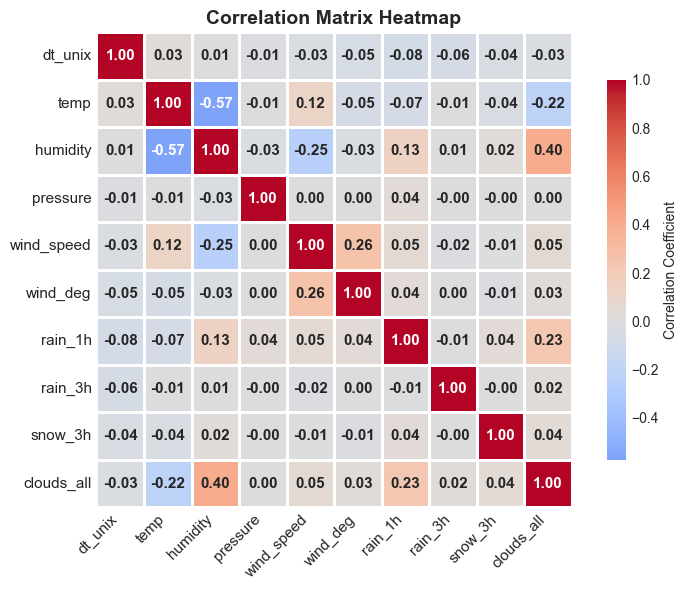

In [1989]:
# แปลง dt_iso ให้เป็น datetime64[ns] ก่อน (ถ้ายังไม่ได้แปลง)
data['dt_iso'] = pd.to_datetime(data['dt_iso'])

# แปลงเป็น Unix timestamp (วินาที)
data['dt_unix'] = data['dt_iso'].astype('int64') // 10**9


numeric_cols = ['dt_unix', 'temp', 'humidity', 'pressure', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all']

corr = data[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={"shrink": 0.8, "label": "Correlation Coefficient"},
    annot_kws={"size": 11, "weight": 'bold'}
)
plt.title('Correlation Matrix Heatmap', fontsize=14, weight='bold')
plt.xticks(fontsize=11, rotation=45, ha='right')
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()


### จากการวิเคราะห์ Heatmap พบว่า อุณหภูมิ (temp) กับความชื้น (humidity) มีความสัมพันธ์เชิงลบค่อนข้างชัด คือค่า -0.57 หมายความว่ายิ่งอุณหภูมิเพิ่มขึ้น ความชื้นจะลดลง ในขณะที่ เมฆทั้งหมด (clouds_all) กับความชื้น มีความสัมพันธ์เชิงบวก คือค่า 0.40 แสดงว่าเมฆกับความชื้นมีแนวโน้มเพิ่มหรือลดไปพร้อมกัน

## 5. Wind roses ทิศทางลมและความเร็วลมของเมือง valencia

C:\Users\suthi\AppData\Local\Temp\ipykernel_25228\2446446540.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  my_cmap = cm.get_cmap('turbo', 8)         # 8 คือจำนวน bin‑1 (มี 7 ขอบ → 8 สี)


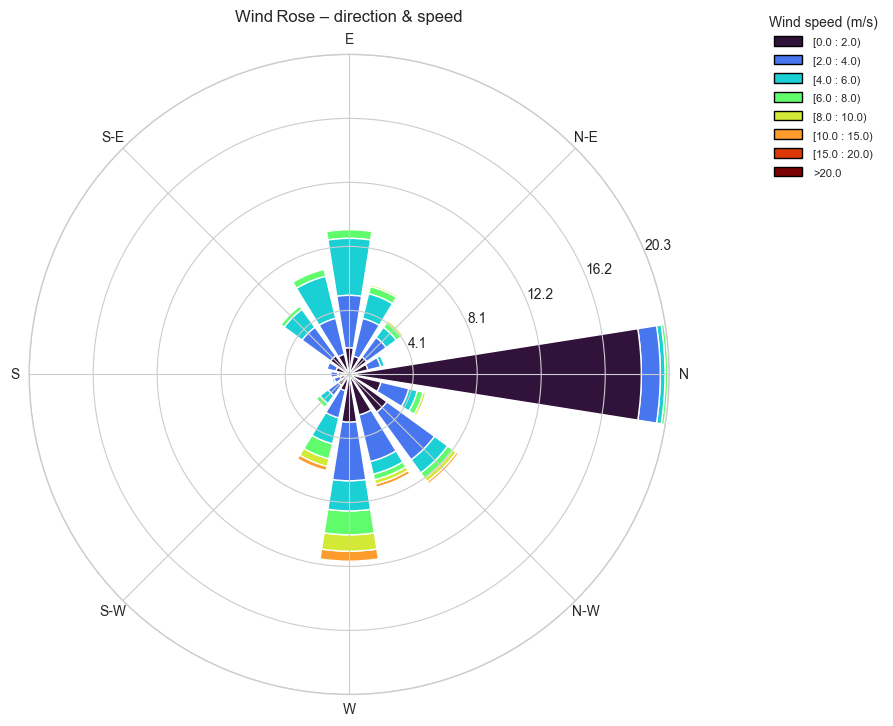

In [ ]:
from matplotlib import cm                 
from windrose import WindroseAxes

fig = plt.figure(figsize=(8, 8))
ax  = WindroseAxes.from_ax(fig=fig)

# เลือก colormap ที่ชอบ (viridis / plasma / turbo ฯลฯ)
my_cmap = cm.get_cmap('turbo', 8)

ax.bar(
    valencia_weather_main['wind_deg'],
    valencia_weather_main['wind_speed'],
    bins=[0, 2, 4, 6, 8, 10, 15, 20],
    normed=True,
    opening=0.8,
    edgecolor='white',
    cmap=my_cmap                    
)

ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

ax.set_legend(title='Wind speed (m/s)', bbox_to_anchor=(1.15, 0.8))
ax.set_title('Wind Rose – direction & speed', va='bottom')
plt.show()


### จากผลการวิเคราะห์พบว่า ทิศทางลมหลัก จะพัดมาจาก ทิศเหนือ (N) โดยส่วนใหญ่มีความเร็วลมอยู่ในช่วง 0 – 2 m/s ขณะที่ลมจาก ทิศตะวันออก (E) และ ทิศใต้ (S) พบในระดับ ความถี่ปานกลาง โดยเฉพาะลมจากทิศใต้มีบางช่วงที่มีความเร็วสูงกว่า 10 m/s

## Part 3: สมมติฐาน (Hypothesis Testing)

## สมมติฐาน ปริมาณเมฆ (clouds_all) และความชื้นสัมพัทธ์ (humidity) ไม่มีความสัมพันธ์กัน

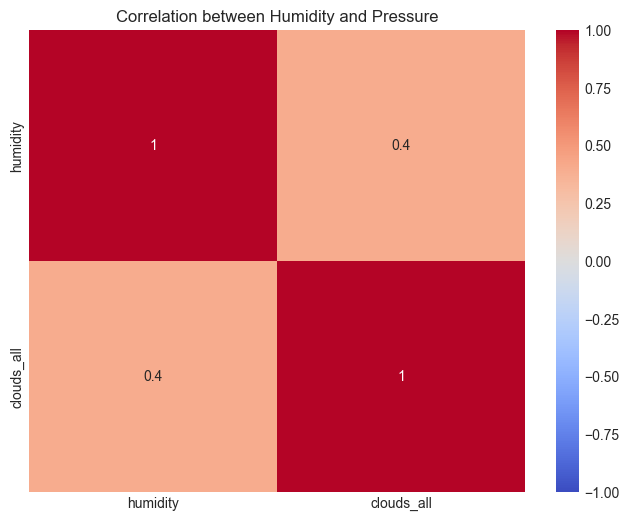

In [2005]:
plt.figure(figsize=(8, 6))
corr = data[['humidity', 'clouds_all']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between Humidity and Pressure')
plt.show()


### จาก heatmap พบว่า ค่า Pearson correlation ระหว่าง humidity และ clouds_all เท่ากับ 0.4 ซึ่งหมายความว่า:

- ทั้งสองตัวแปรมี ความสัมพันธ์เชิงบวกในระดับปานกลาง

- แสดงแนวโน้มว่า เมื่อปริมาณเมฆ (clouds_all) เพิ่มขึ้น ความชื้นสัมพัทธ์ (humidity) ก็มีแนวโน้มเพิ่มขึ้นตาม